# Data Visualization — Quiz (Lectures 1–7)

**Time:** 90 minutes 
**Tools:** Plotly only (`plotly.express` first, then `update_traces` / `update_layout` / `update_xaxes` / `update_yaxes`)

**Your task:** answer each analytical question with **one polished, explanatory visualization**. For every question **you decide which chart type fits best** — and justify the choice in one or two sentences.

**Every figure must have:**
1. An **insight title** that states the finding, not just the variables
2. `template='plotly_white'` and a decluttered layout (no unnecessary gridlines, legends or axis titles)
3. A **CVD-safe palette** — no red/green; grey for context + one accent colour where it helps
4. Colour that **encodes meaning**, not decoration
5. Direct labels or annotations where they help the reader

**Chart types covered in the course** — choose from these:
line chart · sorted bar chart · stacked / 100% stacked bar chart · scatter plot · bubble chart · histogram · box plot · violin plot · choropleth map · treemap

> 💡 Each question has one chart type that fits it best, and the questions together cover most of the list above. If two of your answers use the same chart type, check the question again.


**Submit:** this notebook pushed to your personal repo as `quiz/dataviz_quiz.ipynb`

## The dataset — World Population 1970–2022

**Source:** [World Population Dataset](https://www.kaggle.com/datasets/iamsouravbanerjee/world-population-dataset) on Kaggle, compiled from Worldometer (UN World Population Prospects estimates). **234 rows × 16 columns — one row per country or territory, no missing values.**

| Column | Type | Description |
|---|---|---|
| `Country`, `Capital` | categorical | Country / territory and its capital |
| `Continent` | categorical | Africa, Asia, Europe, North America, Oceania, South America |
| `CCA3` | spatial | ISO-3 country code — use with `locationmode='ISO-3'` |
| `1970 Population` … `2022 Population` | temporal | Population in 1970, 1980, 1990, 2000, 2010, 2015, 2020, 2022 |
| `Area` | numerical | Land area in km² |
| `Density` | numerical | People per km² (2022) |
| `World share (%)` | numerical | Share of world population in 2022 |
| `Rank` | numerical | Rank by 2022 population |

**The next setup cell also gives you `df_long` — the same data in **tidy (long) format** with one row per country per year. Use `df` for one-year questions and `df_long` for questions about change over time**

In [1]:
import pandas as pd
import plotly.express as px
import numpy as np
from pathlib import Path

# The CSV should be in the same folder as this notebook.
csv_path = Path("world_population.csv")
if not csv_path.exists():
    raise FileNotFoundError(
        "world_population.csv was not found. Put the CSV in the same folder as this notebook."
    )
df = pd.read_csv(csv_path)

# Shorter, consistent column names
df = df.rename(columns={
    "Country/Territory": "Country",
    "Area (km²)": "Area",
    "Density (per km²)": "Density",
    "World Population Percentage": "World share (%)"
})

# Tidy (long) version: one row per country per year
year_cols = [c for c in df.columns if c.endswith("Population")]
df_long = df.melt(
    id_vars=["CCA3", "Country", "Continent"],
    value_vars=year_cols,
    var_name="Year",
    value_name="Population"
)
df_long["Year"] = df_long["Year"].str[:4].astype(int)

print(f"Dataset: {df.shape[0]} countries/territories × {df.shape[1]} columns")
print(f"Long format: {df_long.shape[0]} country-year rows")


Dataset: 234 countries/territories × 16 columns
Long format: 1872 country-year rows


---
## Q1 — Which continent is growing fastest?

How has the population of each continent **grown since 1970, relative to its 1970 size** — and which continent is growing fastest?


**Chart choice & justification:** A line chart compares each continent's population index over time, with 1970 set to 100. Indexing removes differences in starting population size, so the steepest rise identifies the fastest relative growth.

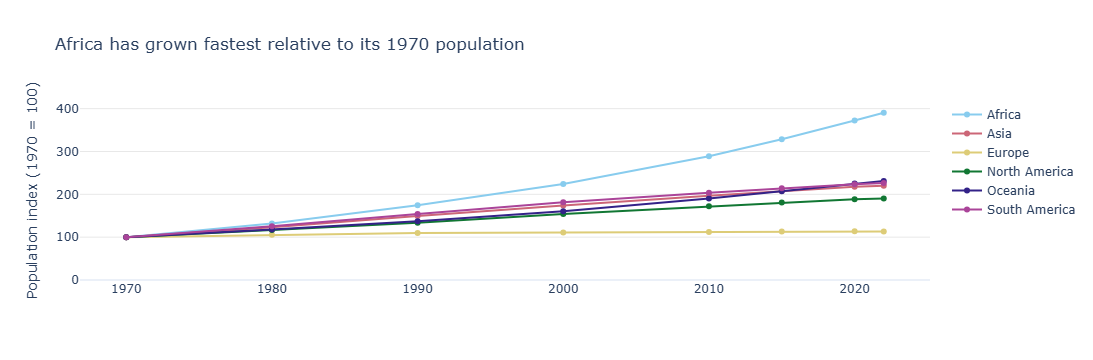

In [2]:
# Q1 — Relative population growth by continent (1970 = 100)
year_cols = [f"{year} Population" for year in [1970, 1980, 1990, 2000, 2010, 2015, 2020, 2022]]
continent_year = df.groupby("Continent")[year_cols].sum()
growth_index = continent_year.div(continent_year["1970 Population"], axis=0) * 100
growth_long = growth_index.reset_index().melt(
    id_vars="Continent", var_name="Year", value_name="Population index"
)
growth_long["Year"] = growth_long["Year"].str.replace(" Population", "", regex=False).astype(int)

fig = px.line(
    growth_long, x="Year", y="Population index", color="Continent",
    markers=True, title="Africa has grown fastest relative to its 1970 population",
    color_discrete_sequence=px.colors.qualitative.Safe
)
fig.update_layout(template="plotly_white", legend_title_text="", xaxis_title="",
                  yaxis_title="Population index (1970 = 100)", hovermode="x unified")
fig.update_xaxes(showgrid=False, dtick=10)
fig.update_yaxes(showgrid=True, gridcolor="#E8E8E8", rangemode="tozero")
fig.show()


---
## Q2 — Which countries added the most people?

Which **15 countries added the most people** between 1970 and 2022 — and how many of them are in **Africa**?

**Chart choice & justification:** A sorted horizontal bar chart makes the 15 largest absolute population gains easy to compare and rank. Colour distinguishes African countries from the rest, making the requested Africa count immediately visible.

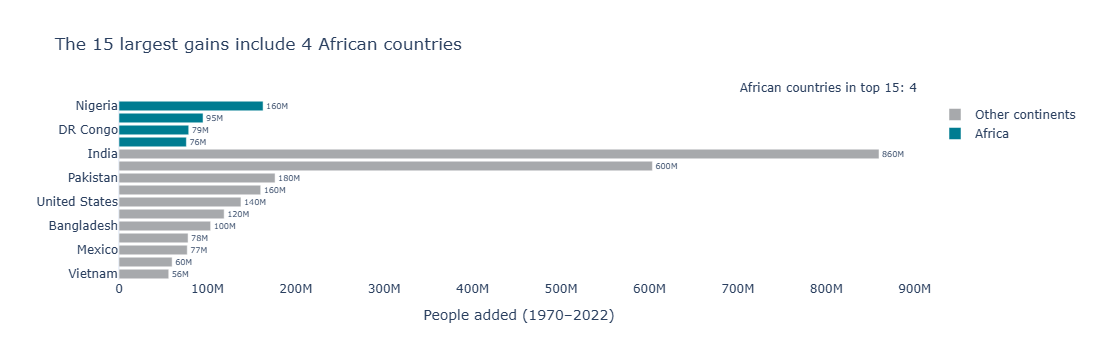

In [3]:
# Q2 — Top 15 countries by absolute population gain, 1970–2022
q2 = df[["Country", "Continent", "1970 Population", "2022 Population"]].copy()
q2["Population added"] = q2["2022 Population"] - q2["1970 Population"]
top15 = q2.nlargest(15, "Population added").sort_values("Population added")
africa_count = int((top15["Continent"] == "Africa").sum())

fig = px.bar(
    top15, x="Population added", y="Country", orientation="h",
    color=top15["Continent"].eq("Africa").map({True: "Africa", False: "Other continents"}),
    color_discrete_map={"Africa": "#007C91", "Other continents": "#A7A9AC"},
    text="Population added",
    title=f"The 15 largest gains include {africa_count} African countries"
)
fig.update_traces(texttemplate="%{text:.2s}", textposition="outside", cliponaxis=False)
fig.update_layout(template="plotly_white", showlegend=True, legend_title_text="",
                  xaxis_title="People added (1970–2022)", yaxis_title="",
                  margin=dict(r=90))
fig.update_xaxes(showgrid=False, tickformat="~s")
fig.update_yaxes(showgrid=False)
fig.add_annotation(x=1, y=1.12, xref="paper", yref="paper",
                   text=f"African countries in top 15: {africa_count}",
                   showarrow=False, xanchor="right")
fig.show()


---
## Q3 — Do bigger countries have more people?

Is there a relationship between a country's **land area** and its **2022 population** — does it differ by **continent**, and which countries clearly break the pattern?

**Chart choice & justification:** A scatter plot is appropriate for comparing two numerical variables across many countries. Logarithmic axes reveal both small and very large countries, while continent colour and selected labels expose notable departures from the overall pattern.

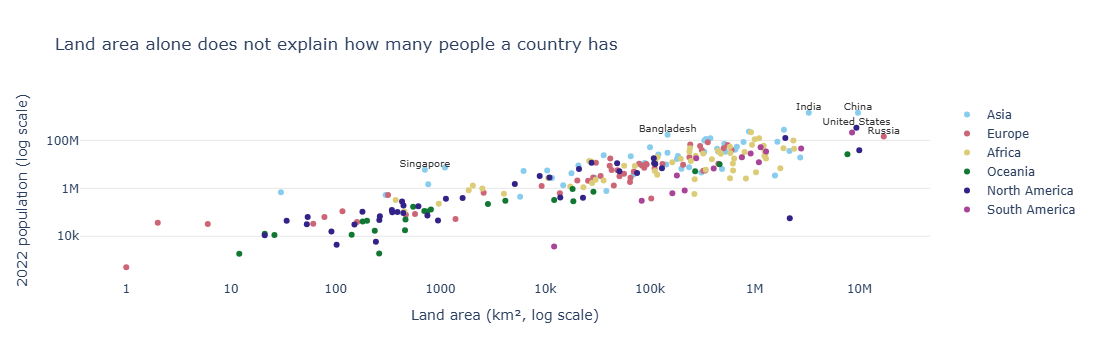

In [4]:
# Q3 — Land area versus 2022 population
q3 = df[["Country", "Continent", "Area", "2022 Population"]].copy()
fig = px.scatter(
    q3, x="Area", y="2022 Population", color="Continent",
    hover_name="Country", log_x=True, log_y=True,
    title="Land area alone does not explain how many people a country has",
    color_discrete_sequence=px.colors.qualitative.Safe
)
# Label a few clear high-population / large-area examples for context.
label_countries = ["China", "India", "United States", "Russia", "Bangladesh", "Singapore"]
labels = q3[q3["Country"].isin(label_countries)]
fig.add_scatter(x=labels["Area"], y=labels["2022 Population"], mode="text",
                text=labels["Country"], textposition="top center",
                textfont=dict(size=10, color="#333333"), showlegend=False,
                hoverinfo="skip")
fig.update_layout(template="plotly_white", xaxis_title="Land area (km², log scale)",
                  yaxis_title="2022 population (log scale)", legend_title_text="")
fig.update_xaxes(showgrid=False)
fig.update_yaxes(showgrid=True, gridcolor="#E8E8E8")
fig.show()


---
## Q4 — How crowded are the continents?

How does **population density vary within and across continents**? Show the spread, not just the average.

**Chart choice & justification:** A box plot shows each continent's median, interquartile range and outliers, so it communicates the spread rather than only an average. A logarithmic vertical axis makes highly skewed country densities readable.

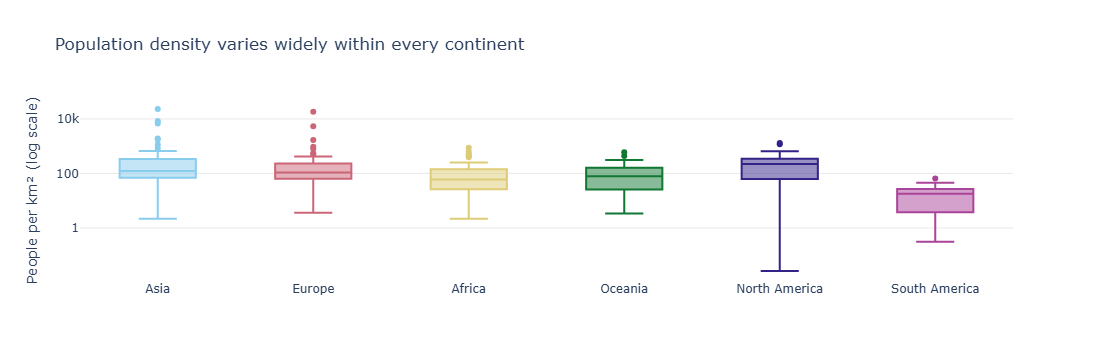

In [5]:
# Q4 — Distribution of population density by continent
fig = px.box(
    df, x="Continent", y="Density", color="Continent", points="outliers",
    log_y=True, title="Population density varies widely within every continent",
    color_discrete_sequence=px.colors.qualitative.Safe
)
fig.update_layout(template="plotly_white", showlegend=False,
                  xaxis_title="", yaxis_title="People per km² (log scale)")
fig.update_xaxes(showgrid=False)
fig.update_yaxes(showgrid=True, gridcolor="#E8E8E8")
fig.show()


---
## Q5 — Where did populations grow — and where did they shrink?

Which countries' populations **grew and which shrank between 2000 and 2022** (percentage change), and where in the world are they?

**Chart choice & justification:** A choropleth map places percentage population change in geographic context and makes regional patterns visible. A diverging brown–teal scale separates population decline from growth without using a red–green combination.

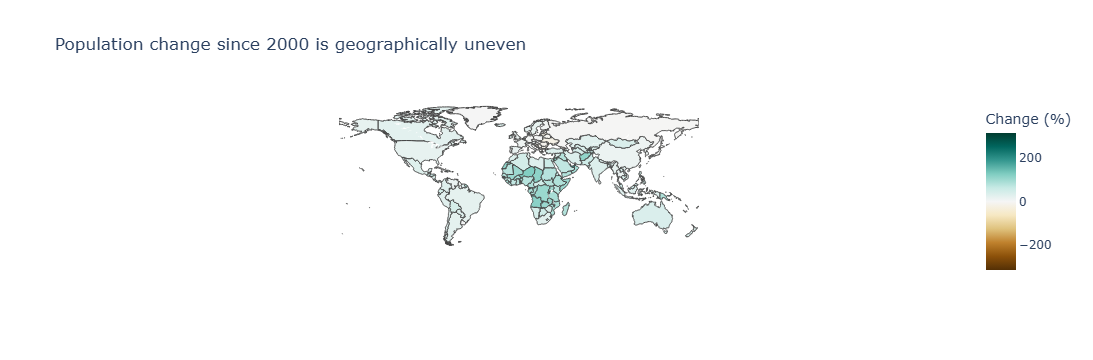

In [6]:
# Q5 — Percentage population change by country, 2000–2022
q5 = df[["Country", "CCA3", "Continent", "2000 Population", "2022 Population"]].copy()
q5["Change (%)"] = (
    (q5["2022 Population"] - q5["2000 Population"]) /
    q5["2000 Population"] * 100
)
fig = px.choropleth(
    q5, locations="CCA3", locationmode="ISO-3", color="Change (%)",
    hover_name="Country", hover_data={"Continent": True, "Change (%)": ":.1f", "CCA3": False},
    color_continuous_scale="BrBG", color_continuous_midpoint=0,
    title="Population change since 2000 is geographically uneven"
)
fig.update_layout(template="plotly_white", geo=dict(showframe=False, showcoastlines=False),
                  coloraxis_colorbar_title="Change (%)")
fig.show()


---
## Q6 — Where do the world's 8 billion people live?

How is the **2022 world population** distributed across **continents and the countries within them**? Show both levels in one figure.

**Chart choice & justification:** A treemap shows the whole 2022 population as nested rectangles: continent first, then country. Rectangle area represents population, allowing both the continental split and the largest countries within each continent to be compared in one figure.

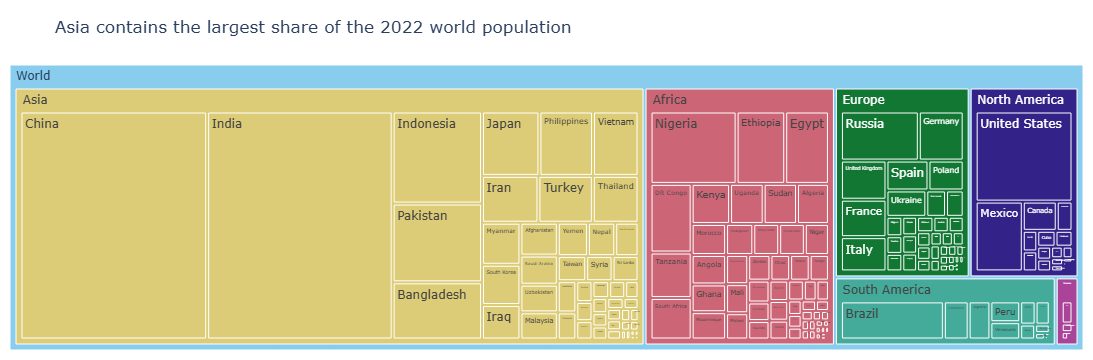

In [7]:
# Q6 — 2022 world population by continent and country
fig = px.treemap(
    df, path=[px.Constant("World"), "Continent", "Country"],
    values="2022 Population", color="Continent",
    color_discrete_sequence=px.colors.qualitative.Safe,
    title="Asia contains the largest share of the 2022 world population"
)
fig.update_traces(root_color="#D9D9D9", tiling=dict(pad=3),
                  hovertemplate="<b>%{label}</b><br>Population: %{value:,}<br>Share of world: %{percentRoot:.1%}<extra></extra>")
fig.update_layout(template="plotly_white", margin=dict(t=65, l=10, r=10, b=10),
                  coloraxis_showscale=False)
fig.show()


---
## Q7 — Whose share of the world is rising?

How have the shares of world population held by **Africa, Asia and Europe** changed from 1970 to 2022? Group the other three continents as `'Rest of the world'`.

**Chart choice & justification:** A 100% stacked bar chart compares the percentage composition of the world population at each selected year. It highlights how Africa, Asia, Europe and the combined remainder change their shares, independent of total world-population growth.

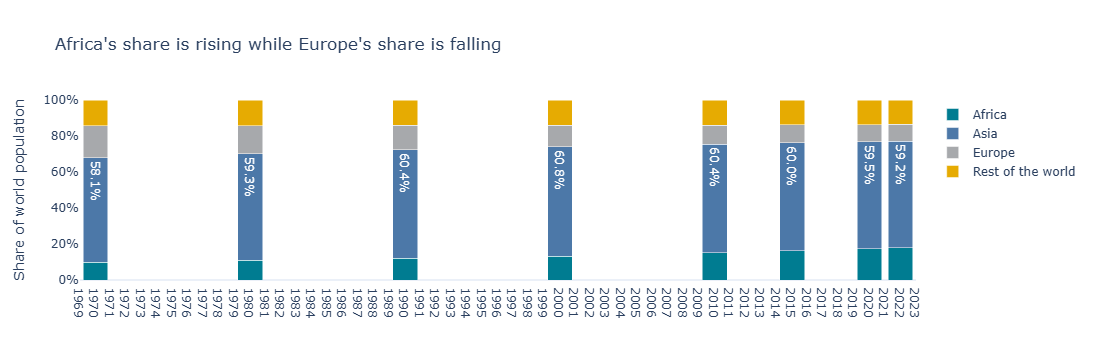

In [8]:
# Q7 — Share of world population by continent group over time
years = [1970, 1980, 1990, 2000, 2010, 2015, 2020, 2022]
totals = df.groupby("Continent")[[f"{y} Population" for y in years]].sum()
groups = pd.DataFrame(index=years)
groups["Africa"] = totals.loc["Africa"].values
groups["Asia"] = totals.loc["Asia"].values
groups["Europe"] = totals.loc["Europe"].values
groups["Rest of the world"] = (
    totals.drop(index=["Africa", "Asia", "Europe"]).sum(axis=0).values
)
shares = groups.div(groups.sum(axis=1), axis=0) * 100
shares_long = shares.reset_index(names="Year").melt(
    id_vars="Year", var_name="Region", value_name="World population share (%)"
)

fig = px.bar(
    shares_long, x="Year", y="World population share (%)", color="Region",
    barmode="stack", text=shares_long["World population share (%)"].round(1),
    title="Africa's share is rising while Europe's share is falling"
    , color_discrete_map={
        "Africa": "#007C91", "Asia": "#4C78A8",
        "Europe": "#A7A9AC", "Rest of the world": "#E6AB02"
    }
)
fig.update_traces(texttemplate="%{text:.1f}%", textposition="inside")
fig.update_layout(template="plotly_white", xaxis_title="", yaxis_title="Share of world population",
                  legend_title_text="", uniformtext_minsize=8, uniformtext_mode="hide")
fig.update_xaxes(showgrid=False, dtick=1)
fig.update_yaxes(range=[0, 100], ticksuffix="%", showgrid=False)
fig.show()


### Submission note

Keep `world_population.csv` in the same folder as this notebook. Run the setup cell first, then run Q1–Q7 in order. Each question produces one Plotly figure.